# Resampling Sentinel-2 imagery

Sentinel-2 records 13 spectral bands at three pixel sizes: 10 m, 20 m and 60 m. Comparing bands, masking clouds
with the 20 m scene classification layer, or matching another dataset all mean putting rasters on a common grid,
that is, resampling. This notebook:

1. searches a public STAC catalogue for Sentinel-2 Level-2A scenes over farmland in central Iowa (USA),
2. reads only a 6 km × 6 km window from each Cloud-Optimized GeoTIFF (COG) over HTTPS, plus a low-resolution
   overview of the whole tile,
3. compares resampling methods: area average versus nearest neighbour when going from 10 m to 60 m, and
   nearest versus bilinear when going from 20 m to 10 m,
4. computes a cloud-masked vegetation index (NDVI) per scene, then repeats that per-scene step for the whole
   2024 growing season in parallel with Ray.

**Data.** Sentinel-2 Level-2A (surface reflectance), Collection 1, as Cloud-Optimized GeoTIFFs on the AWS Registry of
Open Data: <https://registry.opendata.aws/sentinel-2-l2a-cogs/>, found through Element 84's Earth Search STAC API,
<https://earth-search.aws.element84.com/v1> (collection `sentinel-2-c1-l2a`).

**License and attribution.** Access to Copernicus Sentinel data is free, full and open; the Copernicus terms ask
that products derived from it carry a notice. Every figure below shows such derived products:
*Contains modified Copernicus Sentinel data 2024.*

**Requirements:** `pip install pystac-client rasterio numpy pandas matplotlib ray`

All reads are anonymous HTTPS range requests; no cloud account is needed. Each scene costs a few small reads (the
cell in section 2 prints the size of one full band file for comparison). The main analysis reads about half a dozen
scenes; the Ray section reads every scene in the search result (a few dozen).

In [1]:
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.patches import Rectangle
from pystac_client import Client
from rasterio.enums import Resampling
from rasterio.warp import transform
from rasterio.windows import from_bounds

STAC_URL = "https://earth-search.aws.element84.com/v1"
COLLECTION = "sentinel-2-c1-l2a"
CENTER_LON, CENTER_LAT = -93.78, 42.13  # farmland in central Iowa, USA
HALF_WIDTH_M = 3000  # a 6 km x 6 km window
SEASON = "2024-04-01/2024-10-31"
MAX_SCENE_CLOUD = 20  # percent, for the whole 110 km tile

# GDAL settings for reading COGs over HTTP: do not list the remote "directory", retry transient errors.
GDAL_ENV = {"GDAL_DISABLE_READDIR_ON_OPEN": "EMPTY_DIR", "GDAL_HTTP_MAX_RETRY": "3", "GDAL_HTTP_RETRY_DELAY": "1"}

## 1. Search the catalogue

Search for scenes that cover the centre point during the 2024 growing season with less than 20% cloud over the
whole tile. Sentinel-2 products are cut into 110 km × 110 km tiles of the Military Grid Reference System (MGRS);
the point can sit in the overlap of two tiles, so keep only the tile that appears most often.

In [2]:
catalog = Client.open(STAC_URL)
search = catalog.search(
    collections=[COLLECTION],
    intersects={"type": "Point", "coordinates": [CENTER_LON, CENTER_LAT]},
    datetime=SEASON,
    query={"eo:cloud_cover": {"lt": MAX_SCENE_CLOUD}},
)
items = sorted(search.items(), key=lambda it: it.datetime)
tile = pd.Series([it.properties["grid:code"] for it in items]).value_counts().index[0]
items = [it for it in items if it.properties["grid:code"] == tile]

catalogue = pd.DataFrame(
    {
        "date": [it.datetime.date() for it in items],
        "scene cloud %": [round(it.properties["eo:cloud_cover"], 1) for it in items],
        "id": [it.id for it in items],
    }
)
print(f"{len(items)} scenes of tile {tile}")
print("assets:", ", ".join(sorted(items[0].assets)))
catalogue.head(10)

37 scenes of tile MGRS-15TVG
assets: aot, blue, cloud, coastal, granule_metadata, green, nir, nir08, nir09, preview, product_metadata, red, rededge1, rededge2, rededge3, scl, snow, swir16, swir22, thumbnail, tileinfo_metadata, visual, wvp


,date,scene cloud %,id
0,2024-04-08,14.4,S2B_T15TVG_20240408T171018_L2A
1,2024-04-13,0.0,S2A_T15TVG_20240413T171752_L2A
2,2024-04-15,0.0,S2B_T15TVG_20240415T170946_L2A
3,2024-04-23,0.7,S2A_T15TVG_20240423T171652_L2A
4,2024-05-18,1.2,S2B_T15TVG_20240518T171459_L2A
5,2024-05-20,2.9,S2A_T15TVG_20240520T170851_L2A
6,2024-05-23,0.2,S2A_T15TVG_20240523T172147_L2A
7,2024-05-25,16.9,S2B_T15TVG_20240525T170239_L2A
8,2024-05-28,3.7,S2B_T15TVG_20240528T171514_L2A
9,2024-06-09,0.0,S2A_T15TVG_20240609T170704_L2A


## 2. Reading only what is needed

A COG stores each band in internal tiles (blocks) plus a pyramid of reduced-resolution copies ("overviews"), so a
reader can fetch one window, or a coarse version of the whole image, with HTTP range requests instead of
downloading the file.

The window is defined in the tile's own map projection (UTM) and its edges are snapped to multiples of 60 m, so
the 10 m, 20 m and 60 m pixel grids all line up exactly inside it.

In [3]:
crs = items[0].properties["proj:code"]
xs, ys = transform("EPSG:4326", crs, [CENTER_LON], [CENTER_LAT])
cx, cy = round(xs[0] / 60) * 60, round(ys[0] / 60) * 60
bounds = (cx - HALF_WIDTH_M, cy - HALF_WIDTH_M, cx + HALF_WIDTH_M, cy + HALF_WIDTH_M)  # left, bottom, right, top
print("tile CRS:", crs, "| window bounds (m):", bounds)

# A clear mid-summer scene for the detailed look: prefer scenes that cover the whole tile
# (a tile at the edge of a satellite pass is partly empty), then the least cloud.
summer = min(
    (it for it in items if it.datetime.month in (7, 8)),
    key=lambda it: (it.properties.get("s2:nodata_pixel_percentage", 0) > 1, it.properties["eo:cloud_cover"]),
)
print("summer scene:", summer.id, "| scene cloud %:", round(summer.properties["eo:cloud_cover"], 2),
      "| empty %:", round(summer.properties.get("s2:nodata_pixel_percentage", 0), 2))

red_href = summer.assets["red"].href
with urllib.request.urlopen(urllib.request.Request(red_href, method="HEAD"), timeout=30) as resp:
    print(f"the full red-band file is {int(resp.headers['Content-Length']) / 1e6:.0f} MB")
with rasterio.Env(**GDAL_ENV), rasterio.open(red_href) as src:
    print(f"red band: {src.width} x {src.height} pixels of {src.res[0]:.0f} m, "
          f"internal blocks {src.block_shapes[0]}, overview factors {src.overviews(1)}")

tile CRS: EPSG:32615 | window bounds (m): (432540, 4661520, 438540, 4667520)
summer scene: S2A_T15TVG_20240818T171118_L2A | scene cloud %: 0.51 | empty %: 0


the full red-band file is 195 MB


red band: 10980 x 10980 pixels of 10 m, internal blocks (1024, 1024), overview factors [2, 4, 8, 16]


overview (3, 343, 343) read in 3.7 s


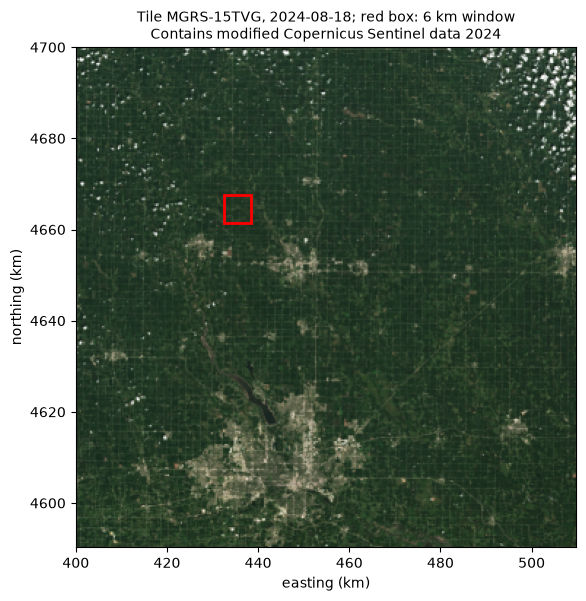

In [4]:
def band_scaling(item, key):
    """(nodata, scale, offset) that turn stored integers into reflectance."""
    band = item.assets[key].extra_fields.get("raster:bands", [{}])[0]
    nodata, scale, offset = band.get("nodata", 0), band.get("scale", 1.0), band.get("offset", 0.0)
    if item.properties.get("earthsearch:boa_offset_applied"):
        # Earth Search's older "sentinel-2-l2a" collection stores values with the offset
        # already removed, so it must not be applied a second time.
        offset = 0.0
    return nodata, scale, offset


def read_band(href, bounds, res=None, resampling=Resampling.nearest, nodata=0, scale=1.0, offset=0.0):
    """Read the window `bounds` from a COG at pixel size `res` (metres) as float32, nodata -> NaN.

    When `res` differs from the file's own pixel size, GDAL resamples while reading and uses
    the closest overview level when one exists.
    """
    with rasterio.Env(**GDAL_ENV), rasterio.open(href) as src:
        res = res or src.res[0]
        window = from_bounds(*bounds, transform=src.transform)
        shape = (round((bounds[3] - bounds[1]) / res), round((bounds[2] - bounds[0]) / res))
        raw = src.read(1, window=window, out_shape=shape, resampling=resampling)
    out = raw.astype("float32") * scale + offset
    out[raw == nodata] = np.nan
    return out


# Quick look: the whole 110 km tile from an overview, about 1/32 of the full resolution.
t0 = time.time()
with rasterio.Env(**GDAL_ENV), rasterio.open(summer.assets["visual"].href) as src:
    factor = 32
    overview = src.read(out_shape=(3, src.height // factor, src.width // factor), resampling=Resampling.average)
    left, bottom, right, top = src.bounds
print(f"overview {overview.shape} read in {time.time() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(np.moveaxis(overview, 0, -1), extent=[left / 1e3, right / 1e3, bottom / 1e3, top / 1e3])
ax.add_patch(Rectangle((bounds[0] / 1e3, bounds[1] / 1e3), 2 * HALF_WIDTH_M / 1e3, 2 * HALF_WIDTH_M / 1e3,
                       fill=False, edgecolor="red", lw=2))
ax.set_xlabel("easting (km)")
ax.set_ylabel("northing (km)")
ax.set_title(f"Tile {tile}, {summer.datetime:%Y-%m-%d}; red box: 6 km window\n"
             "Contains modified Copernicus Sentinel data 2024", fontsize=10)
plt.show()

## 3. The window at native resolution

Read the red and near-infrared bands (10 m), the first short-wave infrared band `swir16` (20 m) and the scene
classification layer `scl` (20 m) for the summer scene. The STAC metadata (`raster:bands`) gives the scale and
offset that turn the stored integers into surface reflectance.

In [5]:
t0 = time.time()
red10 = read_band(summer.assets["red"].href, bounds, None, Resampling.nearest, *band_scaling(summer, "red"))
nir10 = read_band(summer.assets["nir"].href, bounds, None, Resampling.nearest, *band_scaling(summer, "nir"))
swir20 = read_band(summer.assets["swir16"].href, bounds, None, Resampling.nearest, *band_scaling(summer, "swir16"))
scl20 = read_band(summer.assets["scl"].href, bounds)
print(f"read 4 windows in {time.time() - t0:.1f} s")
for name, a in [("red 10 m", red10), ("nir 10 m", nir10), ("swir16 20 m", swir20), ("scl 20 m", scl20)]:
    print(f"{name:12s} shape {a.shape}, range {np.nanmin(a):.3f} to {np.nanmax(a):.3f}")


def ndvi(red, nir):
    """Normalized difference vegetation index, (NIR - red) / (NIR + red)."""
    return (nir - red) / (nir + red)


ndvi10 = ndvi(red10, nir10)
print(f"NDVI at 10 m: mean {np.nanmean(ndvi10):.3f}")

read 4 windows in 5.5 s
red 10 m     shape (600, 600), range 0.017 to 0.526
nir 10 m     shape (600, 600), range 0.058 to 0.768
swir16 20 m  shape (300, 300), range 0.038 to 0.610
scl 20 m     shape (300, 300), range 4.000 to 5.000
NDVI at 10 m: mean 0.837


## 4. Resampling

### 4a. Downsampling, 10 m to 60 m

Three ways to get a 60 m grid from 10 m pixels:

* **area average**: the mean of the 6 × 6 block of 10 m pixels in each 60 m cell, computed here with NumPy,
* **nearest neighbour**: keep one 10 m pixel per 60 m cell and drop the other 35,
* **average on read**: ask GDAL for a 60 m `out_shape` with `Resampling.average`. GDAL starts from the closest
  overview (40 m here) instead of the 10 m data, so it reads less but the result is close to, not identical
  with, the true area average.

Reflectances are resampled first and NDVI is computed afterwards.

nearest neighbour : mean |NDVI - area average| = 0.0219
average on read   : mean |NDVI - area average| = 0.0058


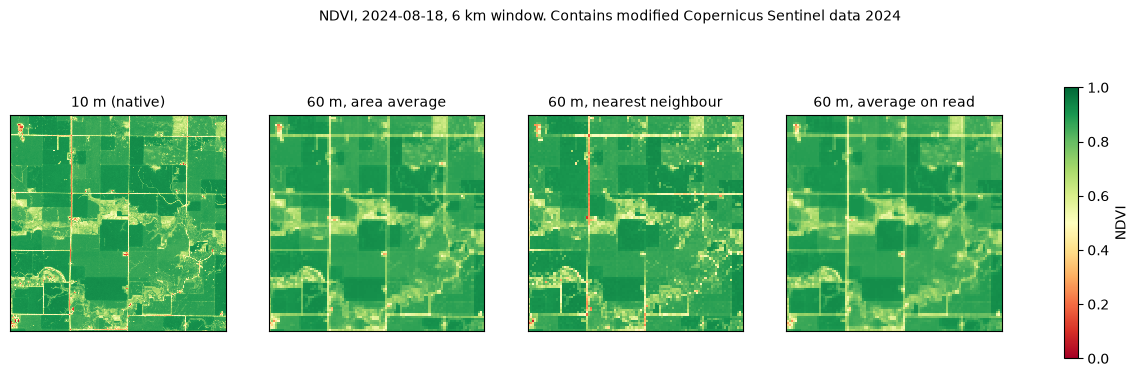

In [6]:
def block_mean(a, k):
    """Average non-overlapping k x k blocks (the window size is a multiple of k)."""
    h, w = a.shape
    return np.nanmean(a.reshape(h // k, k, w // k, k), axis=(1, 3))


k = 6
ndvi60_mean = ndvi(block_mean(red10, k), block_mean(nir10, k))
ndvi60_nearest = ndvi(red10[k // 2::k, k // 2::k], nir10[k // 2::k, k // 2::k])
red60_read = read_band(summer.assets["red"].href, bounds, 60, Resampling.average, *band_scaling(summer, "red"))
nir60_read = read_band(summer.assets["nir"].href, bounds, 60, Resampling.average, *band_scaling(summer, "nir"))
ndvi60_read = ndvi(red60_read, nir60_read)

for name, a in [("nearest neighbour", ndvi60_nearest), ("average on read", ndvi60_read)]:
    diff = np.nanmean(np.abs(a - ndvi60_mean))
    print(f"{name:18s}: mean |NDVI - area average| = {diff:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
panels = [("10 m (native)", ndvi10), ("60 m, area average", ndvi60_mean),
          ("60 m, nearest neighbour", ndvi60_nearest), ("60 m, average on read", ndvi60_read)]
for ax, (title, a) in zip(axes, panels):
    im = ax.imshow(a, cmap="RdYlGn", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label="NDVI")
fig.suptitle(f"NDVI, {summer.datetime:%Y-%m-%d}, 6 km window. Contains modified Copernicus Sentinel data 2024",
             fontsize=10)
plt.show()

Nearest neighbour keeps whatever single pixel falls at the cell centre: roads, field edges and farmsteads either
vanish or fill a whole 60 m cell, so the result is noisier than the area average. For continuous quantities such
as reflectance, area averaging is the usual choice when going to a coarser grid.

### 4b. Upsampling, 20 m to 10 m

To combine the 20 m short-wave infrared band with the 10 m near-infrared band, for example in the moisture index
NDMI = (NIR − SWIR) / (NIR + SWIR), one option is to upsample SWIR to 10 m. Upsampling adds no detail. Nearest
neighbour repeats each 20 m value in a 2 × 2 block; bilinear interpolation blends neighbouring values and smooths
the block edges. The zoomed panels show a 1.5 km corner of the window.

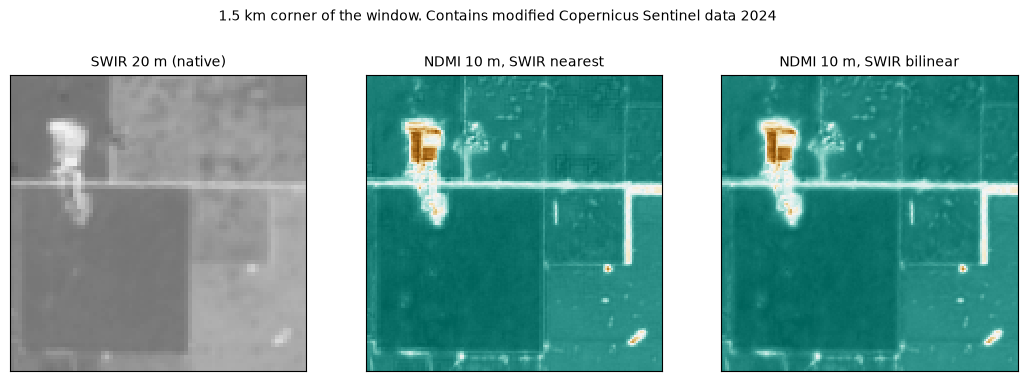

In [7]:
swir10_nearest = read_band(summer.assets["swir16"].href, bounds, 10, Resampling.nearest, *band_scaling(summer, "swir16"))
swir10_bilinear = read_band(summer.assets["swir16"].href, bounds, 10, Resampling.bilinear, *band_scaling(summer, "swir16"))
ndmi_nearest = (nir10 - swir10_nearest) / (nir10 + swir10_nearest)
ndmi_bilinear = (nir10 - swir10_bilinear) / (nir10 + swir10_bilinear)

# Nearest-neighbour upsampling is exact: averaging it back to 20 m returns the original values.
assert np.allclose(block_mean(swir10_nearest, 2), swir20, equal_nan=True)

zoom = np.s_[:150, :150]  # 150 x 150 pixels of 10 m = 1.5 km
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
panels = [("SWIR 20 m (native)", swir20[:75, :75], "Greys_r", (0, 0.4)),
          ("NDMI 10 m, SWIR nearest", ndmi_nearest[zoom], "BrBG", (-0.4, 0.6)),
          ("NDMI 10 m, SWIR bilinear", ndmi_bilinear[zoom], "BrBG", (-0.4, 0.6))]
for ax, (title, a, cmap, (vmin, vmax)) in zip(axes, panels):
    ax.imshow(a, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("1.5 km corner of the window. Contains modified Copernicus Sentinel data 2024", fontsize=10)
plt.show()

### 4c. Categorical layers

The scene classification layer (`scl`) holds class codes (4 = vegetation, 5 = bare soil, 6 = water,
8 to 10 = cloud and thin cirrus, 3 = cloud shadow, ...). Averaging codes would produce meaningless classes, so a categorical
layer is only ever resampled with nearest neighbour. The per-scene step below goes the other way: it brings
red and near-infrared down to the 20 m grid of `scl` with area averaging and leaves the class codes untouched.

## 5. The per-scene step: cloud-masked NDVI

`scene_ndvi` takes plain values (URLs and scaling numbers rather than STAC objects), so the same function can run
in a Ray worker. For one scene it reads red and near-infrared at 20 m (average on read, from the 20 m overview),
reads `scl` at its native 20 m, keeps only pixels classed as vegetation, bare soil or water, and returns the
date, the clear share of the window and the mean NDVI of the clear pixels.

In [8]:
CLEAR_CLASSES = [4, 5, 6]  # vegetation, not vegetated (bare soil), water


def scene_inputs(item):
    """The plain values the per-scene step needs from a STAC item."""
    return {
        "date": item.datetime.date().isoformat(),
        "red": item.assets["red"].href, "red_scaling": band_scaling(item, "red"),
        "nir": item.assets["nir"].href, "nir_scaling": band_scaling(item, "nir"),
        "scl": item.assets["scl"].href,
    }


def scene_ndvi(scene, bounds, res=20):
    """Cloud-masked NDVI of the window for one scene."""
    red = read_band(scene["red"], bounds, res, Resampling.average, *scene["red_scaling"])
    nir = read_band(scene["nir"], bounds, res, Resampling.average, *scene["nir_scaling"])
    scl = read_band(scene["scl"], bounds, res, Resampling.nearest)  # class codes: nearest only
    clear = np.isin(scl, CLEAR_CLASSES) & np.isfinite(red) & np.isfinite(nir)
    index = np.where(clear, ndvi(red, nir), np.nan).astype("float32")
    return {
        "date": pd.Timestamp(scene["date"]),
        "clear %": round(100.0 * clear.mean(), 1),
        "mean NDVI": float(np.nanmean(index)) if clear.any() else np.nan,
        "ndvi": index,
    }


scenes = [scene_inputs(it) for it in items]
print(scenes[0]["date"], scenes[0]["red_scaling"])

2024-04-08 (0, 0.0001, -0.1)


Run it on five scenes, one after another: the middle scene (by date) of May, June, July, August and October.
April and September are left out only to keep the figure to five panels; change the months in the loop to
pick others.

5 scenes read one after another in 9 s (1.7 s per scene)


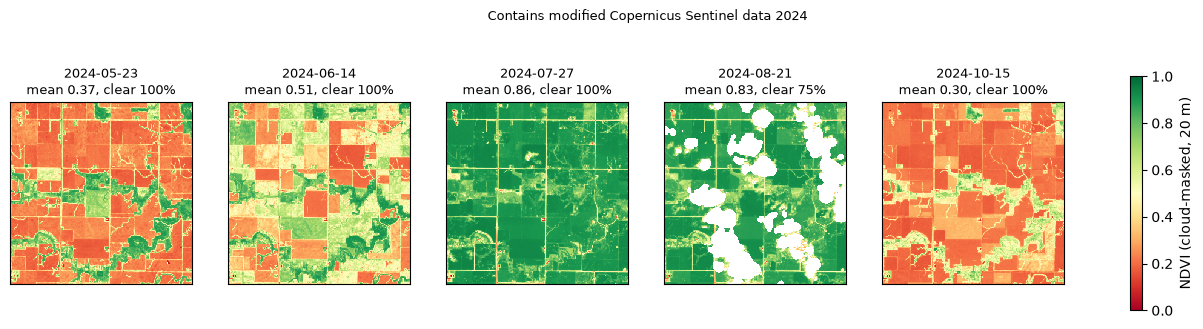

,clear %,mean NDVI
date,,
2024-05-23,100.0,0.366
2024-06-14,100.0,0.506
2024-07-27,100.0,0.857
2024-08-21,74.7,0.831
2024-10-15,100.0,0.301


In [9]:
picked = []
for month in (5, 6, 7, 8, 10):
    in_month = [s for s, it in zip(scenes, items) if it.datetime.month == month]
    if in_month:
        picked.append(in_month[len(in_month) // 2])

t0 = time.time()
monthly = [scene_ndvi(s, bounds) for s in picked]
serial_seconds = time.time() - t0
print(f"{len(picked)} scenes read one after another in {serial_seconds:.0f} s "
      f"({serial_seconds / len(picked):.1f} s per scene)")

fig, axes = plt.subplots(1, len(monthly), figsize=(3.4 * len(monthly), 3.8))
for ax, r in zip(np.atleast_1d(axes), monthly):
    im = ax.imshow(r["ndvi"], cmap="RdYlGn", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"{r['date']:%Y-%m-%d}\nmean {r['mean NDVI']:.2f}, clear {r['clear %']:.0f}%", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label="NDVI (cloud-masked, 20 m)")
fig.suptitle("Contains modified Copernicus Sentinel data 2024", fontsize=9)
plt.show()
pd.DataFrame(monthly).drop(columns="ndvi").set_index("date").round(3)

The fields are mostly bare in spring, reach their greenest in mid-summer and drop again as crops mature and are
harvested in autumn; white patches are pixels removed by the cloud mask.

## Scaling out with Ray

Each scene is processed independently, so the per-scene step parallelises directly. Wrap `scene_ndvi` as a Ray
task and submit one task per scene in the search result. Each task reads its own windows straight from the
COGs over HTTPS; only the small result (a few numbers and a 300 × 300 NDVI array) returns to the driver.

`ray.init(num_cpus=4)` starts a small local Ray instance. On a Ray cluster, `ray.init()` (or `ray.init(address=...)`)
connects to it instead and the same code spreads the tasks over its nodes. To process more, widen `SEASON`,
raise `MAX_SCENE_CLOUD`, or enlarge the window, then run the cells again.

In [10]:
import ray

ray.init(num_cpus=4)

remote_scene_ndvi = ray.remote(scene_ndvi)

t0 = time.time()
refs = [remote_scene_ndvi.remote(s, bounds) for s in scenes]
season = pd.DataFrame(ray.get(refs)).set_index("date").sort_index()
ray_seconds = time.time() - t0
print(f"{len(scenes)} scenes read by Ray tasks on 4 CPUs in {ray_seconds:.0f} s "
      f"({ray_seconds / len(scenes):.1f} s per scene, versus {serial_seconds / len(picked):.1f} s one by one)")

37 scenes read by Ray tasks on 4 CPUs in 23 s (0.6 s per scene, versus 1.7 s one by one)


_These timings come from one run on a shared machine. The reads are network-bound, so the numbers change with the network and the machine's load; they are not a benchmark._

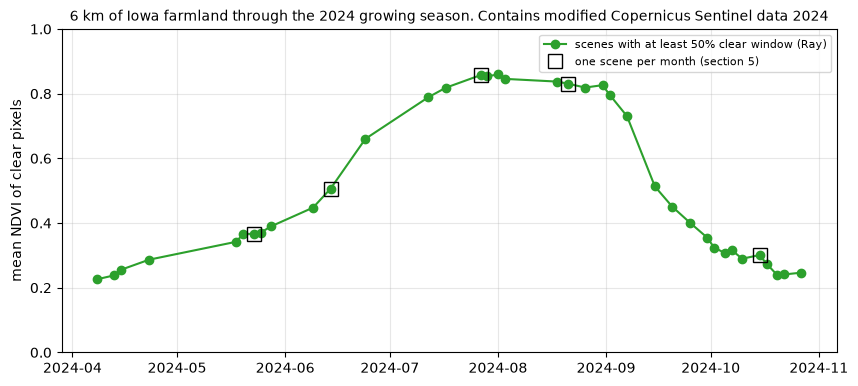

37 of 37 scenes pass the 50% clear threshold; peak mean NDVI 0.86 on 2024-08-01


In [11]:
MIN_CLEAR = 50  # percent of the window; scenes below this are shown but not trusted

ok = season["clear %"] >= MIN_CLEAR
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(season.index[ok], season.loc[ok, "mean NDVI"], "o-", color="tab:green",
        label=f"scenes with at least {MIN_CLEAR}% clear window (Ray)")
if (~ok).any():  # only when some scene falls short; with MAX_SCENE_CLOUD = 20 there may be none
    ax.plot(season.index[~ok], season.loc[~ok, "mean NDVI"], "x", color="grey",
            label=f"under {MIN_CLEAR}% clear")
ax.plot([r["date"] for r in monthly], [r["mean NDVI"] for r in monthly], "s", mfc="none", mec="black", ms=10,
        label="one scene per month (section 5)")
ax.set_ylabel("mean NDVI of clear pixels")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
ax.set_title("6 km of Iowa farmland through the 2024 growing season. "
             "Contains modified Copernicus Sentinel data 2024", fontsize=10)
plt.show()

# The monthly scenes are a subset of the season, so the values must match.
for r in monthly:
    assert np.isclose(season.loc[r["date"], "mean NDVI"], r["mean NDVI"], equal_nan=True)
print(f"{ok.sum()} of {len(season)} scenes pass the {MIN_CLEAR}% clear threshold; "
      f"peak mean NDVI {season.loc[ok, 'mean NDVI'].max():.2f} on {season.loc[ok, 'mean NDVI'].idxmax():%Y-%m-%d}")

In [12]:
ray.shutdown()